###Wellbeing Forecasting (Time-Series)
#
#### Objective
#####Predict a student's **next_week_wellbeing_score** based on their current and historical weekly data. This enables proactive intervention — if we predict a student's wellbeing will decline next week, we can act early.
#
#### Why Time-Series?
#####Unlike Static regression and classification, this task uses **temporal patterns** — how features change over weeks — to predict the future.

#### Section 1: Install and Import Libraries

In [1]:
# ============================================================
# SECTION 1: INSTALL AND IMPORT LIBRARIES
# ============================================================
# !pip install pandas numpy scikit-learn matplotlib seaborn xgboost lightgbm tensorflow

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

try:
    import xgboost as xgb
    HAS_XGB = True
    print("[OK] XGBoost loaded")
except: HAS_XGB = False; print("[WARN] XGBoost not found")

try:
    import lightgbm as lgb
    HAS_LGB = True
    print("[OK] LightGBM loaded")
except: HAS_LGB = False; print("[WARN] LightGBM not found")

try:
    import tensorflow as tf
    from tensorflow.keras.models import Sequential
    from tensorflow.keras.layers import LSTM, GRU, Dense, Dropout
    from tensorflow.keras.callbacks import EarlyStopping
    HAS_TF = True
    print("[OK] TensorFlow loaded")
except: HAS_TF = False; print("[WARN] TensorFlow not found")

plt.style.use('seaborn-v0_8-whitegrid')

print("\n" + "=" * 60)
print("WELLBEING FORECASTING (TIME-SERIES)")
print("=" * 60)


[OK] XGBoost loaded
[OK] LightGBM loaded
[OK] TensorFlow loaded

WELLBEING FORECASTING (TIME-SERIES)


####Section 2: Load and Inspect Data

In [2]:
# ============================================================
# SECTION 2: LOAD AND INSPECT DATA
# ============================================================
df = pd.read_csv('student_wellbeing_dataset.csv')
print(f"Dataset shape: {df.shape}")
print(f"Students: {df['student_id'].nunique()}")
print(f"Weeks per student: {df['week'].nunique()}")
print(f"\nTarget: next_week_wellbeing_score")
print(f"  Range: [{df['next_week_wellbeing_score'].min():.1f}, {df['next_week_wellbeing_score'].max():.1f}]")
print(f"  Mean: {df['next_week_wellbeing_score'].mean():.2f}")

Dataset shape: (2400, 26)
Students: 300
Weeks per student: 8

Target: next_week_wellbeing_score
  Range: [28.0, 96.2]
  Mean: 68.79


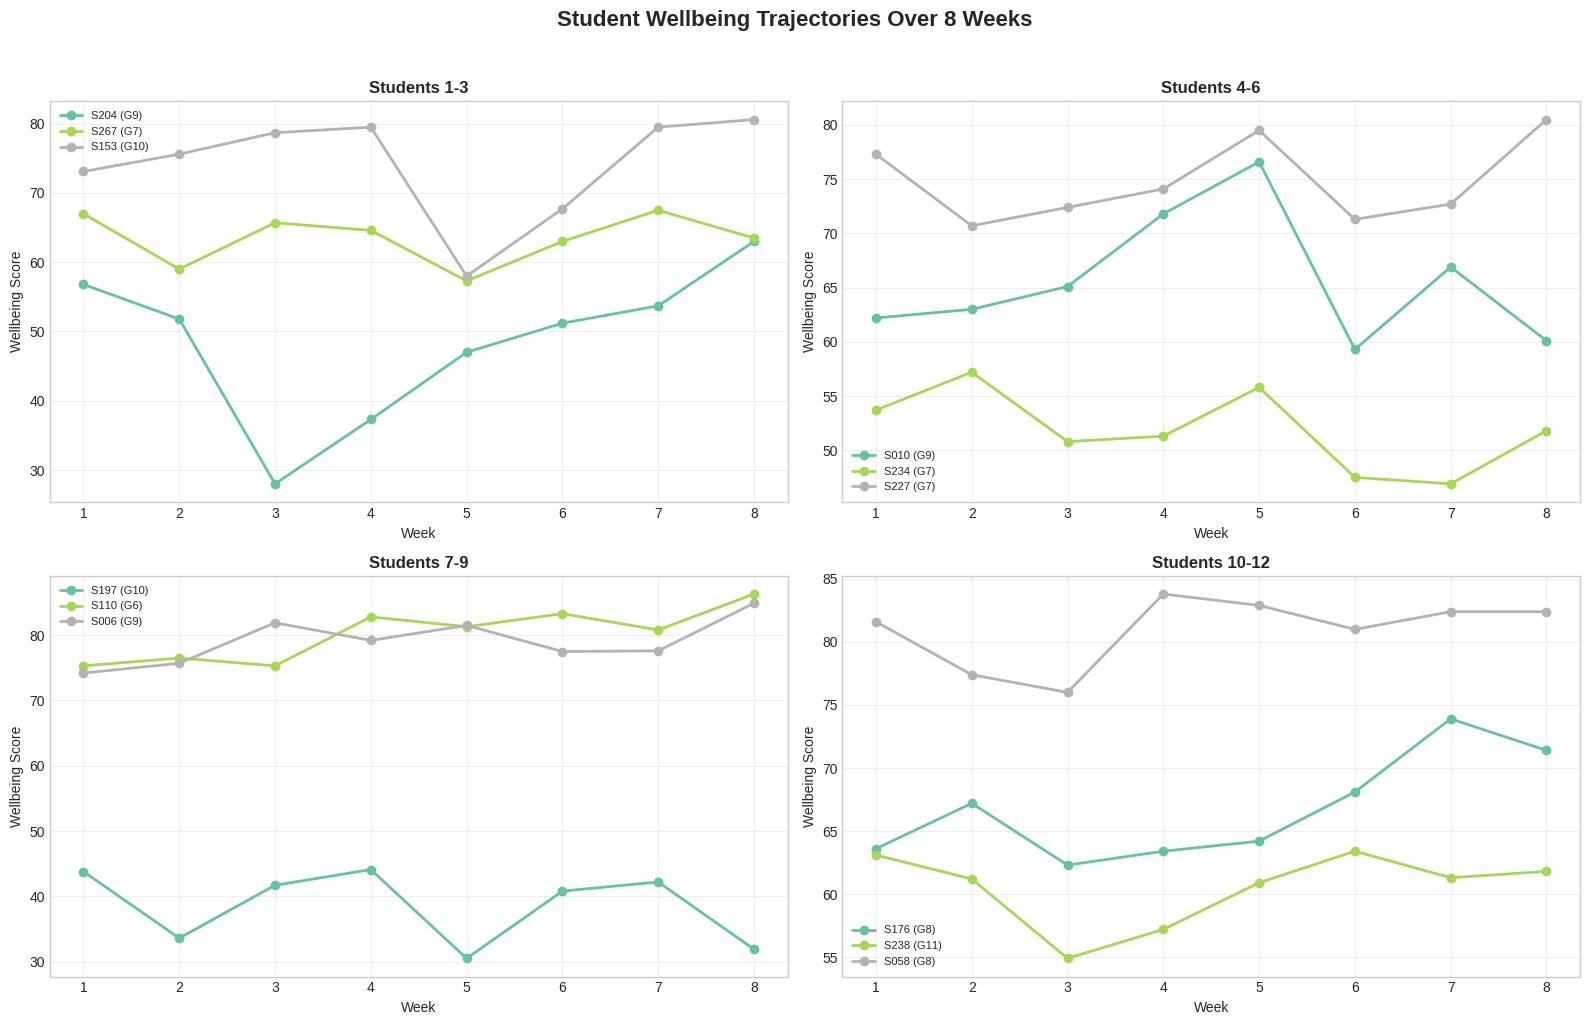

In [3]:
# ============================================================
# EDA CHART 1: WELLBEING TRAJECTORIES (Multiple Students)
# ============================================================
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes = axes.flatten()

# Plot 4 different student types
sample_ids = df['student_id'].unique()
np.random.seed(42)
selected = np.random.choice(sample_ids, 12, replace=False)

titles = ['Students 1-3', 'Students 4-6', 'Students 7-9', 'Students 10-12']
colors_ts = plt.cm.Set2(np.linspace(0, 1, 3))

for idx in range(4):
    for j in range(3):
        sid = selected[idx * 3 + j]
        student = df[df['student_id'] == sid].sort_values('week')
        axes[idx].plot(student['week'], student['composite_wellbeing_score'],
                       marker='o', linewidth=2, color=colors_ts[j],
                       label=f'{sid} (G{student["grade"].iloc[0]})')
    axes[idx].set_title(titles[idx], fontweight='bold')
    axes[idx].set_xlabel('Week')
    axes[idx].set_ylabel('Wellbeing Score')
    axes[idx].set_xticks(range(1, 9))
    axes[idx].legend(fontsize=8)
    axes[idx].grid(True, alpha=0.3)

fig.suptitle('Student Wellbeing Trajectories Over 8 Weeks', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('c4_chart1_trajectories.png', dpi=150, bbox_inches='tight')
plt.show()

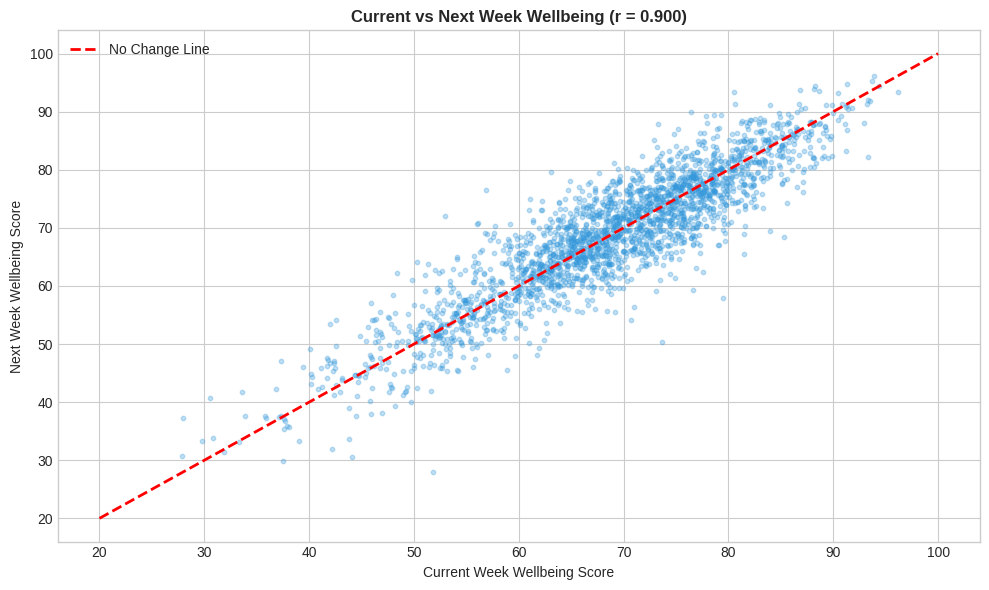

In [4]:
# ============================================================
# EDA CHART 2: CURRENT vs NEXT WEEK WELLBEING
# ============================================================
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(df['composite_wellbeing_score'], df['next_week_wellbeing_score'],
           alpha=0.3, s=10, color='#3498db')
ax.plot([20, 100], [20, 100], 'r--', linewidth=2, label='No Change Line')
r = df['composite_wellbeing_score'].corr(df['next_week_wellbeing_score'])
ax.set_title(f'Current vs Next Week Wellbeing (r = {r:.3f})', fontweight='bold')
ax.set_xlabel('Current Week Wellbeing Score')
ax.set_ylabel('Next Week Wellbeing Score')
ax.legend()
plt.tight_layout()
plt.savefig('c4_chart2_current_vs_next.png', dpi=150, bbox_inches='tight')
plt.show()

#### Section 3: Time-Series Feature Engineering
#
##### This is the **most unique part** of this notebook. We create temporal features that capture how a student's indicators change over time.

In [5]:
# ============================================================
# SECTION 3: TIME-SERIES FEATURE ENGINEERING
# ============================================================
print("\n" + "=" * 60)
print("SECTION 3: TIME-SERIES FEATURE ENGINEERING")
print("=" * 60)

# Sort by student and week for proper lag computation
df = df.sort_values(['student_id', 'week']).reset_index(drop=True)

# --- Lag Features (previous week values) ---
for col in ['composite_wellbeing_score', 'avg_exam_score', 'stress_level', 'attendance_rate']:
    df[f'{col}_lag1'] = df.groupby('student_id')[col].shift(1)
    df[f'{col}_lag2'] = df.groupby('student_id')[col].shift(2)
    print(f"[+] {col}_lag1, {col}_lag2")

# --- Rolling Statistics (3-week window) ---
for col in ['composite_wellbeing_score', 'stress_level']:
    df[f'{col}_rolling_mean3'] = df.groupby('student_id')[col].transform(
        lambda x: x.rolling(3, min_periods=1).mean()
    )
    df[f'{col}_rolling_std3'] = df.groupby('student_id')[col].transform(
        lambda x: x.rolling(3, min_periods=1).std()
    )
    print(f"[+] {col}_rolling_mean3, {col}_rolling_std3")

# --- Delta Features (week-over-week change) ---
df['score_delta'] = df.groupby('student_id')['avg_exam_score'].diff()
df['stress_delta'] = df.groupby('student_id')['stress_level'].diff()
df['wellbeing_delta'] = df.groupby('student_id')['composite_wellbeing_score'].diff()
print("[+] score_delta, stress_delta, wellbeing_delta")

# --- Momentum (direction of change) ---
df['momentum'] = df['composite_wellbeing_score_lag1'] - df['composite_wellbeing_score_lag2']
print("[+] momentum")

# --- Cumulative Stress (burden over time) ---
df['cumulative_stress_3w'] = df.groupby('student_id')['stress_level'].transform(
    lambda x: x.rolling(3, min_periods=1).sum()
)
print("[+] cumulative_stress_3w")

# --- Attendance Trend (slope over last 3 weeks) ---
def rolling_slope(series, window=3):
    result = []
    for i in range(len(series)):
        if i < window - 1:
            result.append(0)
        else:
            y = series.iloc[i-window+1:i+1].values
            x = np.arange(window)
            if len(y) == window:
                slope, _, _, _, _ = stats.linregress(x, y)
                result.append(slope)
            else:
                result.append(0)
    return pd.Series(result, index=series.index)

df['attendance_trend'] = df.groupby('student_id')['attendance_rate'].transform(
    lambda x: rolling_slope(x, 3)
)
print("[+] attendance_trend")

# --- Exponential Moving Average ---
df['wellbeing_ema'] = df.groupby('student_id')['composite_wellbeing_score'].transform(
    lambda x: x.ewm(alpha=0.3, min_periods=1).mean()
)
print("[+] wellbeing_ema")

# Fill NaN from lag/rolling operations
df = df.fillna(0)
print(f"\nTotal features after engineering: {len(df.columns)}")
print(f"NaN values remaining: {df.isnull().sum().sum()}")



SECTION 3: TIME-SERIES FEATURE ENGINEERING
[+] composite_wellbeing_score_lag1, composite_wellbeing_score_lag2
[+] avg_exam_score_lag1, avg_exam_score_lag2
[+] stress_level_lag1, stress_level_lag2
[+] attendance_rate_lag1, attendance_rate_lag2
[+] composite_wellbeing_score_rolling_mean3, composite_wellbeing_score_rolling_std3
[+] stress_level_rolling_mean3, stress_level_rolling_std3
[+] score_delta, stress_delta, wellbeing_delta
[+] momentum
[+] cumulative_stress_3w
[+] attendance_trend
[+] wellbeing_ema

Total features after engineering: 45
NaN values remaining: 0


####Section 4: Temporal Train/Test Split

In [6]:
# ============================================================
# SECTION 4: TEMPORAL TRAIN/TEST SPLIT
# ============================================================
# CRITICAL: We split by TIME, not randomly!
# Train: Weeks 1-6, Test: Weeks 7-8
# This prevents data leakage from future to past

print("\n" + "=" * 60)
print("SECTION 4: TEMPORAL SPLIT")
print("=" * 60)

train_mask = df['week'] <= 6
test_mask = df['week'] >= 7

drop_cols = ['student_id', 'risk_label', 'next_week_wellbeing_score']
feature_cols = [c for c in df.columns if c not in drop_cols]
target = 'next_week_wellbeing_score'

X_train = df.loc[train_mask, feature_cols]
y_train = df.loc[train_mask, target]
X_test = df.loc[test_mask, feature_cols]
y_test = df.loc[test_mask, target]

print(f"Train (weeks 1-6): {X_train.shape[0]} samples")
print(f"Test  (weeks 7-8): {X_test.shape[0]} samples")
print(f"Features: {X_train.shape[1]}")

# StandardScaler (fitted on train only - prevent data leakage)
std_scaler = StandardScaler()
X_train_scaled = pd.DataFrame(std_scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(std_scaler.transform(X_test), columns=X_test.columns, index=X_test.index)
print("\n[OK] StandardScaler applied (fitted on train only)")

print("\n" + "=" * 60)
print("PART 1 COMPLETE: Time-series preprocessing done!")
print("Proceed to Part 2 for Model Training & Evaluation.")
print("=" * 60)


SECTION 4: TEMPORAL SPLIT
Train (weeks 1-6): 1800 samples
Test  (weeks 7-8): 600 samples
Features: 42

[OK] StandardScaler applied (fitted on train only)

PART 1 COMPLETE: Time-series preprocessing done!
Proceed to Part 2 for Model Training & Evaluation.


#### Section 5: Model Training

In [7]:
# ============================================================
# SETUP
# ============================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from scipy import stats
import joblib
import warnings
warnings.filterwarnings('ignore')

try:
    import xgboost as xgb; HAS_XGB = True
except: HAS_XGB = False
try:
    import lightgbm as lgb; HAS_LGB = True
except: HAS_LGB = False
try:
    import tensorflow as tf
    from tensorflow.keras.models import Sequential
    from tensorflow.keras.layers import LSTM, GRU, Dense, Dropout
    from tensorflow.keras.callbacks import EarlyStopping
    HAS_TF = True
except: HAS_TF = False

plt.style.use('seaborn-v0_8-whitegrid')

# --- Recreate full pipeline ---
df = pd.read_csv('student_wellbeing_dataset.csv')
df = df.sort_values(['student_id', 'week']).reset_index(drop=True)

for col in ['composite_wellbeing_score', 'avg_exam_score', 'stress_level', 'attendance_rate']:
    df[f'{col}_lag1'] = df.groupby('student_id')[col].shift(1)
    df[f'{col}_lag2'] = df.groupby('student_id')[col].shift(2)

for col in ['composite_wellbeing_score', 'stress_level']:
    df[f'{col}_rolling_mean3'] = df.groupby('student_id')[col].transform(lambda x: x.rolling(3, min_periods=1).mean())
    df[f'{col}_rolling_std3'] = df.groupby('student_id')[col].transform(lambda x: x.rolling(3, min_periods=1).std())

df['score_delta'] = df.groupby('student_id')['avg_exam_score'].diff()
df['stress_delta'] = df.groupby('student_id')['stress_level'].diff()
df['wellbeing_delta'] = df.groupby('student_id')['composite_wellbeing_score'].diff()
df['momentum'] = df['composite_wellbeing_score_lag1'] - df['composite_wellbeing_score_lag2']
df['cumulative_stress_3w'] = df.groupby('student_id')['stress_level'].transform(lambda x: x.rolling(3, min_periods=1).sum())

def rolling_slope(series, window=3):
    result = []
    for i in range(len(series)):
        if i < window - 1: result.append(0)
        else:
            y = series.iloc[i-window+1:i+1].values; x = np.arange(window)
            slope, _, _, _, _ = stats.linregress(x, y)
            result.append(slope)
    return pd.Series(result, index=series.index)

df['attendance_trend'] = df.groupby('student_id')['attendance_rate'].transform(lambda x: rolling_slope(x, 3))
df['wellbeing_ema'] = df.groupby('student_id')['composite_wellbeing_score'].transform(lambda x: x.ewm(alpha=0.3, min_periods=1).mean())
df = df.fillna(0)

drop_cols = ['student_id', 'risk_label', 'next_week_wellbeing_score']
feature_cols = [c for c in df.columns if c not in drop_cols]
target = 'next_week_wellbeing_score'

X_train = df.loc[df['week'] <= 6, feature_cols]
y_train = df.loc[df['week'] <= 6, target]
X_test = df.loc[df['week'] >= 7, feature_cols]
y_test = df.loc[df['week'] >= 7, target]

std_scaler = StandardScaler()
X_train_scaled = pd.DataFrame(std_scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(std_scaler.transform(X_test), columns=X_test.columns, index=X_test.index)

all_results = {}
all_models = {}
all_predictions = {}
colors_bar = ['#e74c3c', '#3498db', '#2ecc71', '#f39c12', '#9b59b6']

def evaluate_forecast(y_true, y_pred, model_name):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    # MASE: Mean Absolute Scaled Error (vs naive forecast)
    naive = np.abs(np.diff(y_true)).mean()
    mase = mae / naive if naive > 0 else float('inf')
    # Directional Accuracy
    actual_dir = np.sign(np.diff(np.concatenate([[y_true.iloc[0]], y_true.values])))
    pred_dir = np.sign(np.diff(np.concatenate([[y_pred[0]], y_pred])))
    dir_acc = (actual_dir == pred_dir).mean() * 100

    print(f"\n{'='*50}")
    print(f"  {model_name} - Forecast Results")
    print(f"{'='*50}")
    print(f"  MAE:          {mae:.4f}")
    print(f"  RMSE:         {rmse:.4f}")
    print(f"  R2:           {r2:.4f}")
    print(f"  MASE:         {mase:.4f}")
    print(f"  Dir. Accuracy: {dir_acc:.1f}%")
    return {'MAE': mae, 'RMSE': rmse, 'R2': r2, 'MASE': mase, 'Dir_Accuracy': dir_acc}

print("=" * 60)
print("SECTION 5: MODEL TRAINING")
print("=" * 60)


SECTION 5: MODEL TRAINING


In [8]:
# ============================================================
# MODEL 1: LINEAR REGRESSION (Baseline)
# ============================================================
print("\n" + "#" * 50)
print("# MODEL 1: LINEAR REGRESSION (Baseline)")
print("#" * 50)

lr = LinearRegression()
lr.fit(X_train_scaled, y_train)
y_pred_lr = lr.predict(X_test_scaled)
all_results['Linear Regression'] = evaluate_forecast(y_test, y_pred_lr, "Linear Regression")
all_models['Linear Regression'] = lr
all_predictions['Linear Regression'] = y_pred_lr


##################################################
# MODEL 1: LINEAR REGRESSION (Baseline)
##################################################

  Linear Regression - Forecast Results
  MAE:          3.3976
  RMSE:         4.2328
  R2:           0.8708
  MASE:         0.4706
  Dir. Accuracy: 71.2%


In [9]:
# ============================================================
# MODEL 2: XGBOOST REGRESSOR
# ============================================================
print("\n" + "#" * 50)
print("# MODEL 2: XGBOOST REGRESSOR")
print("#" * 50)

if HAS_XGB:
    xgb_model = xgb.XGBRegressor(
        n_estimators=200, max_depth=5, learning_rate=0.05,
        subsample=0.8, colsample_bytree=0.8, random_state=42
    )
    xgb_model.fit(X_train_scaled, y_train)
    y_pred_xgb = xgb_model.predict(X_test_scaled)
    all_results['XGBoost'] = evaluate_forecast(y_test, y_pred_xgb, "XGBoost")
    all_models['XGBoost'] = xgb_model
    all_predictions['XGBoost'] = y_pred_xgb
else:
    print("[SKIP] XGBoost not installed")


##################################################
# MODEL 2: XGBOOST REGRESSOR
##################################################

  XGBoost - Forecast Results
  MAE:          3.3448
  RMSE:         4.2726
  R2:           0.8683
  MASE:         0.4633
  Dir. Accuracy: 71.3%


In [10]:
# ============================================================
# MODEL 3: LIGHTGBM REGRESSOR
# ============================================================
print("\n" + "#" * 50)
print("# MODEL 3: LIGHTGBM REGRESSOR")
print("#" * 50)

if HAS_LGB:
    lgb_model = lgb.LGBMRegressor(
        n_estimators=200, max_depth=5, learning_rate=0.05,
        subsample=0.8, colsample_bytree=0.8, random_state=42, verbose=-1
    )
    lgb_model.fit(X_train_scaled, y_train)
    y_pred_lgb = lgb_model.predict(X_test_scaled)
    all_results['LightGBM'] = evaluate_forecast(y_test, y_pred_lgb, "LightGBM")
    all_models['LightGBM'] = lgb_model
    all_predictions['LightGBM'] = y_pred_lgb
else:
    print("[SKIP] LightGBM not installed")


##################################################
# MODEL 3: LIGHTGBM REGRESSOR
##################################################

  LightGBM - Forecast Results
  MAE:          3.2685
  RMSE:         4.1254
  R2:           0.8772
  MASE:         0.4527
  Dir. Accuracy: 72.0%


In [11]:
# ============================================================
# MODEL 4 & 5: LSTM & GRU (Deep Learning)
# ============================================================
lstm_history = None
gru_history = None

if HAS_TF:
    # Reshape data for LSTM/GRU: (samples, timesteps=1, features)
    X_train_dl = X_train_scaled.values.reshape(-1, 1, X_train_scaled.shape[1])
    X_test_dl = X_test_scaled.values.reshape(-1, 1, X_test_scaled.shape[1])

    early_stop = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

    # --- LSTM ---
    print("\n" + "#" * 50)
    print("# MODEL 4: LSTM")
    print("#" * 50)

    lstm_model = Sequential([
        LSTM(64, input_shape=(1, X_train_scaled.shape[1]), return_sequences=True),
        Dropout(0.2),
        LSTM(32),
        Dropout(0.2),
        Dense(16, activation='relu'),
        Dense(1)
    ])
    lstm_model.compile(optimizer='adam', loss='mse', metrics=['mae'])
    lstm_history = lstm_model.fit(
        X_train_dl, y_train, epochs=100, batch_size=32,
        validation_split=0.2, callbacks=[early_stop], verbose=0
    )
    y_pred_lstm = lstm_model.predict(X_test_dl, verbose=0).flatten()
    all_results['LSTM'] = evaluate_forecast(y_test, y_pred_lstm, "LSTM")
    all_models['LSTM'] = lstm_model
    all_predictions['LSTM'] = y_pred_lstm

    # --- GRU ---
    print("\n" + "#" * 50)
    print("# MODEL 5: GRU")
    print("#" * 50)

    gru_model = Sequential([
        GRU(64, input_shape=(1, X_train_scaled.shape[1]), return_sequences=True),
        Dropout(0.2),
        GRU(32),
        Dropout(0.2),
        Dense(16, activation='relu'),
        Dense(1)
    ])
    gru_model.compile(optimizer='adam', loss='mse', metrics=['mae'])
    gru_history = gru_model.fit(
        X_train_dl, y_train, epochs=100, batch_size=32,
        validation_split=0.2, callbacks=[early_stop], verbose=0
    )
    y_pred_gru = gru_model.predict(X_test_dl, verbose=0).flatten()
    all_results['GRU'] = evaluate_forecast(y_test, y_pred_gru, "GRU")
    all_models['GRU'] = gru_model
    all_predictions['GRU'] = y_pred_gru
else:
    print("[SKIP] TensorFlow not installed - LSTM & GRU skipped")


##################################################
# MODEL 4: LSTM
##################################################

  LSTM - Forecast Results
  MAE:          3.6462
  RMSE:         4.6135
  R2:           0.8465
  MASE:         0.5050
  Dir. Accuracy: 70.2%

##################################################
# MODEL 5: GRU
##################################################

  GRU - Forecast Results
  MAE:          65.8662
  RMSE:         66.5972
  R2:           -30.9923
  MASE:         9.1225
  Dir. Accuracy: 67.8%


#### Section 6: Evaluation & Visualization

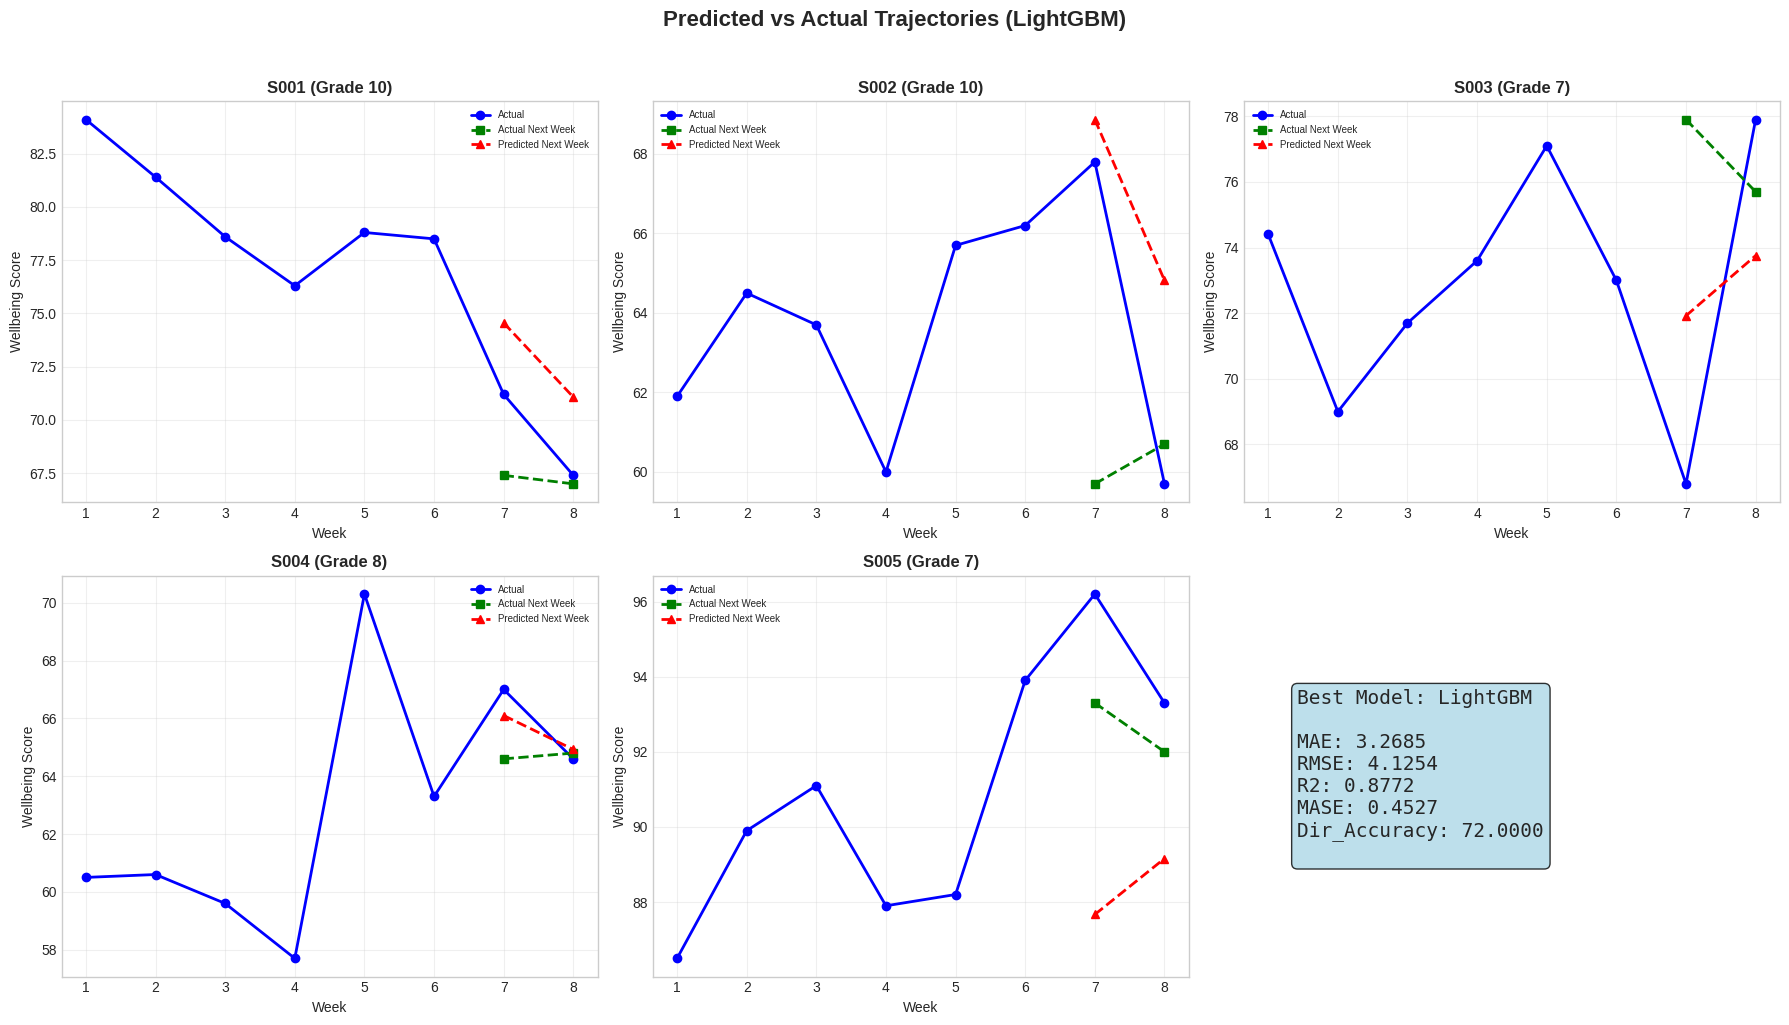

In [12]:
# ============================================================
# EVAL CHART 1: PREDICTED vs ACTUAL TRAJECTORIES (5 Students)
# ============================================================
results_df = pd.DataFrame(all_results).T
best_name = results_df['R2'].idxmax()
best_pred = all_predictions[best_name]

test_df = df[df['week'] >= 7].copy()
test_df['predicted'] = best_pred

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()
sample_students = test_df['student_id'].unique()[:5]

for i, sid in enumerate(sample_students):
    full_student = df[df['student_id'] == sid].sort_values('week')
    pred_student = test_df[test_df['student_id'] == sid].sort_values('week')

    axes[i].plot(full_student['week'], full_student['composite_wellbeing_score'],
                 'b-o', linewidth=2, label='Actual', markersize=6)
    axes[i].plot(pred_student['week'], pred_student['next_week_wellbeing_score'],
                 'g--s', linewidth=2, label='Actual Next Week', markersize=6)
    axes[i].plot(pred_student['week'], pred_student['predicted'],
                 'r--^', linewidth=2, label='Predicted Next Week', markersize=6)
    axes[i].set_title(f'{sid} (Grade {full_student["grade"].iloc[0]})', fontweight='bold')
    axes[i].set_xlabel('Week')
    axes[i].set_ylabel('Wellbeing Score')
    axes[i].legend(fontsize=7)
    axes[i].set_xticks(range(1, 9))
    axes[i].grid(True, alpha=0.3)

# Summary in last subplot
axes[5].axis('off')
summary_text = f"Best Model: {best_name}\n\n"
for metric, val in all_results[best_name].items():
    summary_text += f"{metric}: {val:.4f}\n"
axes[5].text(0.1, 0.5, summary_text, fontsize=14, family='monospace',
             verticalalignment='center', bbox=dict(boxstyle='round', facecolor='lightblue', alpha=0.8))

fig.suptitle(f'Predicted vs Actual Trajectories ({best_name})', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('c4_chart3_trajectories_predicted.png', dpi=150, bbox_inches='tight')
plt.show()


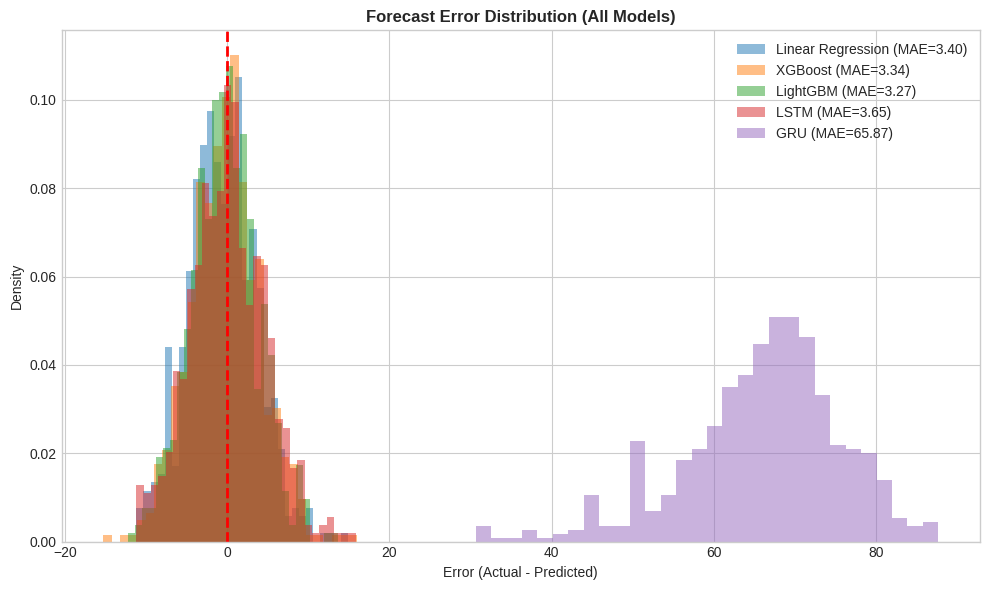

In [13]:
# ============================================================
# EVAL CHART 2: FORECAST ERROR DISTRIBUTION
# ============================================================
fig, ax = plt.subplots(figsize=(10, 6))
for name, pred in all_predictions.items():
    errors = y_test.values - pred
    ax.hist(errors, bins=30, alpha=0.5, label=f'{name} (MAE={all_results[name]["MAE"]:.2f})', density=True)
ax.axvline(0, color='red', linestyle='--', linewidth=2)
ax.set_title('Forecast Error Distribution (All Models)', fontweight='bold')
ax.set_xlabel('Error (Actual - Predicted)')
ax.set_ylabel('Density')
ax.legend()
plt.tight_layout()
plt.savefig('c4_chart4_error_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

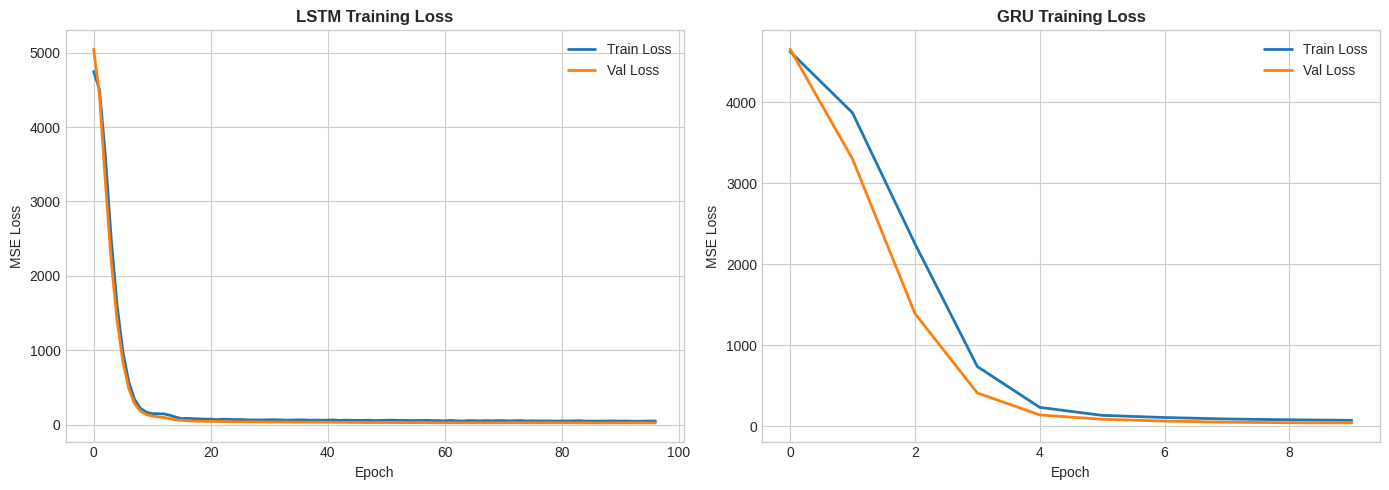

In [14]:
# ============================================================
# EVAL CHART 3: TRAINING LOSS CURVES (LSTM/GRU)
# ============================================================
if HAS_TF and lstm_history and gru_history:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].plot(lstm_history.history['loss'], label='Train Loss', linewidth=2)
    axes[0].plot(lstm_history.history['val_loss'], label='Val Loss', linewidth=2)
    axes[0].set_title('LSTM Training Loss', fontweight='bold')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('MSE Loss')
    axes[0].legend()

    axes[1].plot(gru_history.history['loss'], label='Train Loss', linewidth=2)
    axes[1].plot(gru_history.history['val_loss'], label='Val Loss', linewidth=2)
    axes[1].set_title('GRU Training Loss', fontweight='bold')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('MSE Loss')
    axes[1].legend()

    plt.tight_layout()
    plt.savefig('c4_chart5_loss_curves.png', dpi=150, bbox_inches='tight')
    plt.show()
else:
    print("[SKIP] Loss curves not available (TensorFlow not installed)")


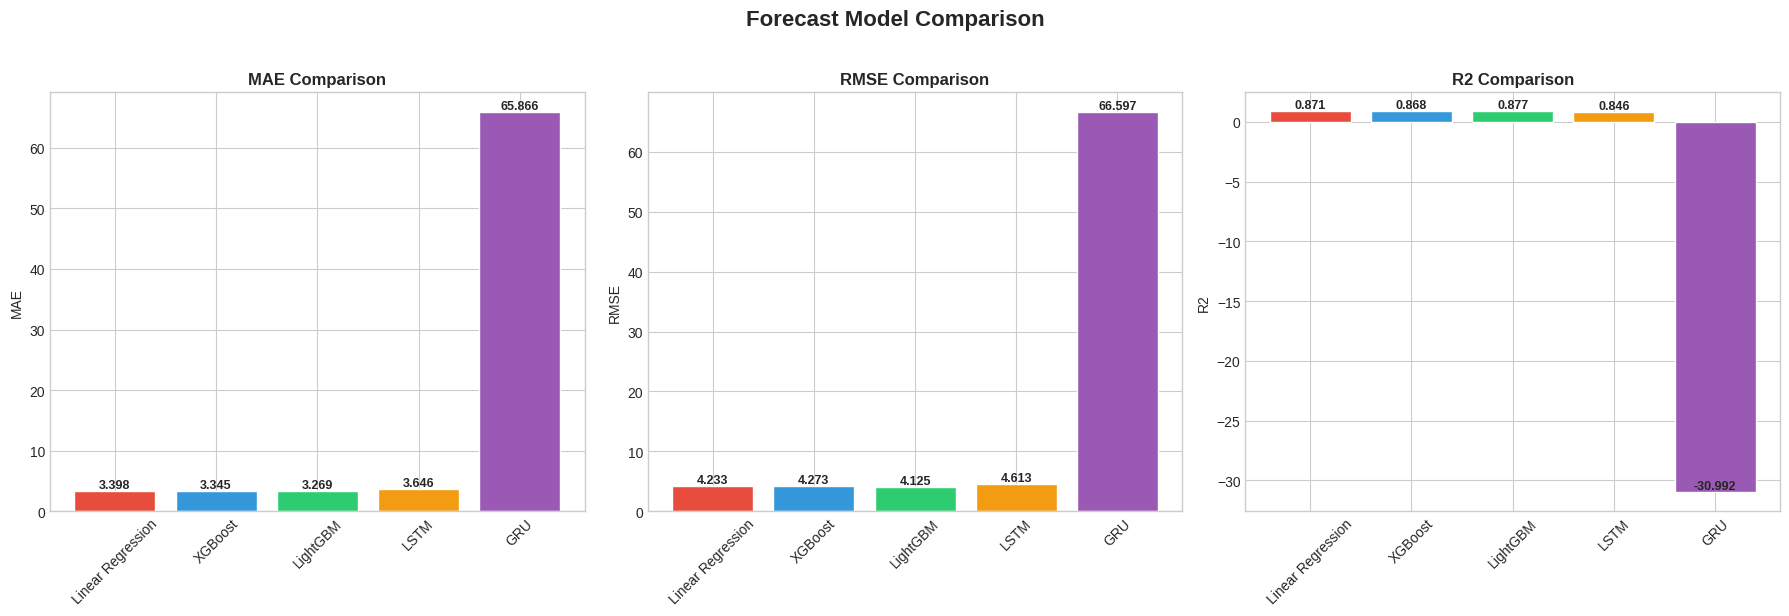

In [15]:
# ============================================================
# EVAL CHART 4: MODEL COMPARISON BAR CHART
# ============================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
metrics_to_plot = ['MAE', 'RMSE', 'R2']

for i, metric in enumerate(metrics_to_plot):
    model_names = list(all_results.keys())
    values = [all_results[m][metric] for m in model_names]
    bars = axes[i].bar(model_names, values, color=colors_bar[:len(model_names)], edgecolor='white')
    axes[i].set_title(f'{metric} Comparison', fontweight='bold')
    axes[i].set_ylabel(metric)
    axes[i].tick_params(axis='x', rotation=45)
    for bar, val in zip(bars, values):
        axes[i].text(bar.get_x() + bar.get_width()/2, bar.get_height(),
                     f'{val:.3f}', ha='center', va='bottom', fontsize=9, fontweight='bold')

fig.suptitle('Forecast Model Comparison', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('c4_chart6_model_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

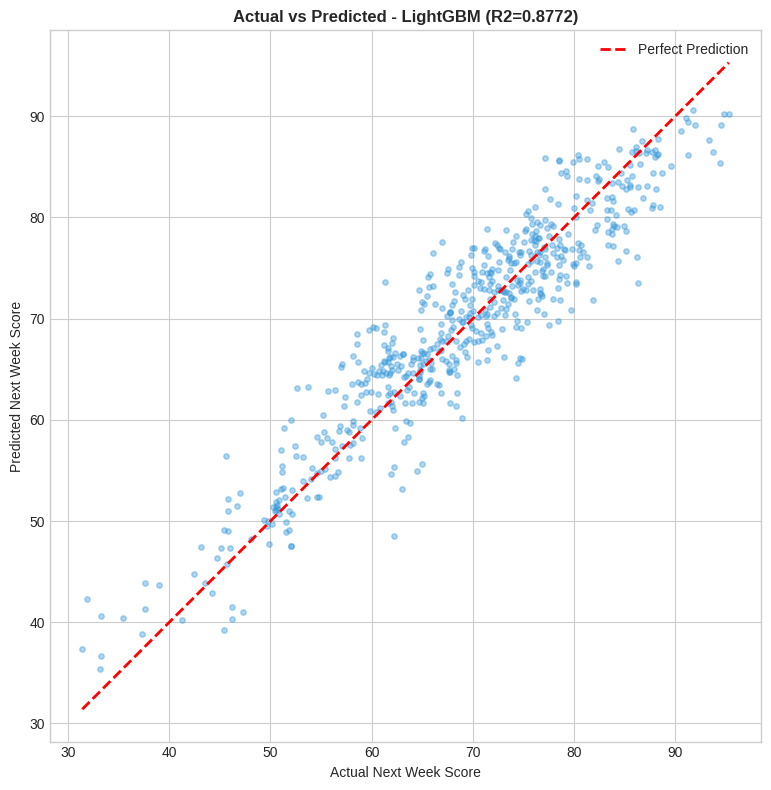

In [16]:
# ============================================================
# EVAL CHART 5: ACTUAL vs PREDICTED SCATTER (Best Model)
# ============================================================
fig, ax = plt.subplots(figsize=(8, 8))
ax.scatter(y_test, best_pred, alpha=0.4, s=15, color='#3498db')
min_v, max_v = min(y_test.min(), best_pred.min()), max(y_test.max(), best_pred.max())
ax.plot([min_v, max_v], [min_v, max_v], 'r--', linewidth=2, label='Perfect Prediction')
ax.set_title(f'Actual vs Predicted - {best_name} (R2={all_results[best_name]["R2"]:.4f})', fontweight='bold')
ax.set_xlabel('Actual Next Week Score')
ax.set_ylabel('Predicted Next Week Score')
ax.legend()
ax.set_aspect('equal')
plt.tight_layout()
plt.savefig('c4_chart7_actual_vs_predicted.png', dpi=150, bbox_inches='tight')
plt.show()

#### Section 7: Final Summary & Export

In [17]:
print("\n" + "=" * 70)
print("FINAL FORECAST MODEL COMPARISON")
print("=" * 70)
print(results_df.round(4).to_string())

print(f"\n*** BEST MODEL: {best_name} ***")
for metric, val in all_results[best_name].items():
    print(f"    {metric}: {val:.4f}")

# Save best model
if best_name not in ['LSTM', 'GRU']:
    joblib.dump(all_models[best_name], 'best_forecast_model.pkl')
    print(f"\nModel saved: best_forecast_model.pkl")
elif HAS_TF:
    all_models[best_name].save('best_forecast_model.keras')
    print(f"\nModel saved: best_forecast_model.keras")

joblib.dump(std_scaler, 'forecast_scaler.pkl')
results_df.to_csv('forecast_results.csv')
print("Scaler saved: forecast_scaler.pkl")
print("Results saved: forecast_results.csv")

print("\n" + "=" * 60)
print("COMPLETE: Wellbeing Forecasting Model built!")
print("=" * 60)


FINAL FORECAST MODEL COMPARISON
                       MAE     RMSE       R2    MASE  Dir_Accuracy
Linear Regression   3.3976   4.2328   0.8708  0.4706       71.1667
XGBoost             3.3448   4.2726   0.8683  0.4633       71.3333
LightGBM            3.2685   4.1254   0.8772  0.4527       72.0000
LSTM                3.6462   4.6135   0.8465  0.5050       70.1667
GRU                65.8662  66.5972 -30.9923  9.1225       67.8333

*** BEST MODEL: LightGBM ***
    MAE: 3.2685
    RMSE: 4.1254
    R2: 0.8772
    MASE: 0.4527
    Dir_Accuracy: 72.0000

Model saved: best_forecast_model.pkl
Scaler saved: forecast_scaler.pkl
Results saved: forecast_results.csv

COMPLETE: Wellbeing Forecasting Model built!
